# Demo 1: The Language of AI (Tensors) and Physics-Informed Neural Networks

**From Equation to World Models: AI and the Simulation of Physics** · SIET talk

This notebook has two parts:

1. **Tensors**: vectors, matrices and tensors in PyTorch, and why a neural network is "just" linear algebra plus a nonlinearity.
2. **A Physics-Informed Neural Network (PINN)**: a network that learns the motion of a damped spring from a handful of data points by also obeying Newton's law. At the end, it *discovers* an unknown physical constant.

Everything runs on a laptop CPU in a couple of minutes.

In [1]:
import math, time
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from IPython.display import clear_output

torch.manual_seed(0)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
print("PyTorch", torch.__version__)

Matplotlib is building the font cache; this may take a moment.


PyTorch 2.14.0


---
## Part 1: Everything is a tensor

| Rank | Name | Example in physics | Example in AI |
|---|---|---|---|
| 0 | scalar | temperature, mass | the loss value |
| 1 | vector | velocity $\vec v$ | a word embedding |
| 2 | matrix | stress tensor $\sigma_{ij}$ | the weights of one layer |
| 3+ | tensor | a fluid field over space and time | a batch of videos |

In [2]:
scalar = torch.tensor(9.81)                        # g, rank 0
vector = torch.tensor([1.0, 0.0, 0.5, 0.0, 2.0, -1.0])  # particle state (x, y, z, vx, vy, vz), rank 1
matrix = torch.randn(3, 3)                          # rank 2
# A batch of 8 fluid simulations, 50 time steps, 3 channels (pressure, vx, vy), on a 64x64 grid
fluid = torch.randn(8, 50, 3, 64, 64)              # rank 5

for name, t in [("scalar", scalar), ("vector", vector), ("matrix", matrix), ("fluid batch", fluid)]:
    print(f"{name:12s} rank={t.ndim}  shape={tuple(t.shape)}  numbers={t.numel():,}")

scalar       rank=0  shape=()  numbers=1
vector       rank=1  shape=(6,)  numbers=6
matrix       rank=2  shape=(3, 3)  numbers=9
fluid batch  rank=5  shape=(8, 50, 3, 64, 64)  numbers=4,915,200


### Similarity is a dot product

Two vectors point the same way when their **cosine similarity** $\cos\theta = \dfrac{\vec a\cdot\vec b}{\|\vec a\|\|\vec b\|}$ is close to 1. Embeddings in language models, recommendation systems and search all rely on this one operation.

In [3]:
v_ball1 = torch.tensor([3.0, 4.0])
v_ball2 = torch.tensor([6.0, 8.1])     # almost the same direction
v_ball3 = torch.tensor([-4.0, 3.0])    # perpendicular

cos = nn.functional.cosine_similarity
print("ball1 vs ball2:", cos(v_ball1, v_ball2, dim=0).item())
print("ball1 vs ball3:", cos(v_ball1, v_ball3, dim=0).item())

ball1 vs ball2: 0.9999822974205017
ball1 vs ball3: 0.0


### A matrix is a transformation, and a neural layer is a matrix plus a bend

One layer of a neural network computes

$$\mathbf h = \sigma(W\mathbf x + \mathbf b)$$

$W$ rotates, stretches and shears space. $\mathbf b$ shifts it. The nonlinearity $\sigma$ (here $\tanh$) **bends** it. Stacking layers bends space again and again until the data becomes easy to separate or predict.

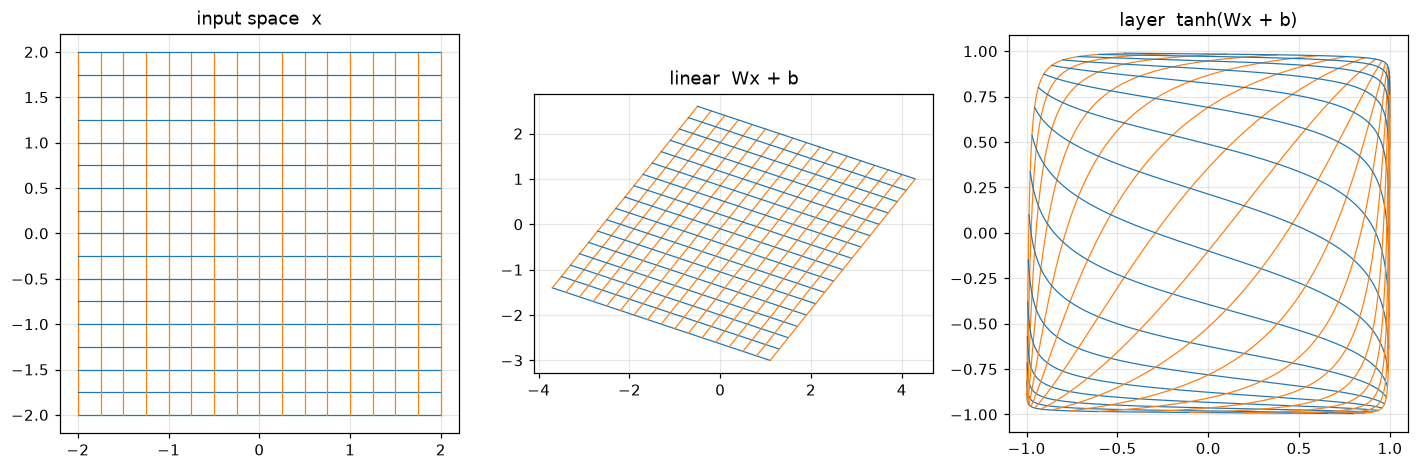

In [4]:
# Build a square grid of lines
lines = []
for c in np.linspace(-2, 2, 17):
    s = np.linspace(-2, 2, 200)
    lines.append(np.stack([s, np.full_like(s, c)], 1))
    lines.append(np.stack([np.full_like(s, c), s], 1))
lines = [torch.tensor(l, dtype=torch.float32) for l in lines]

W = torch.tensor([[1.2, 0.8], [-0.4, 1.0]])   # rotation + shear + stretch
b = torch.tensor([0.3, -0.2])

stages = {
    "input space  x": lambda p: p,
    "linear  Wx + b": lambda p: p @ W.T + b,
    "layer  tanh(Wx + b)": lambda p: torch.tanh(p @ W.T + b),
}
fig, axes = plt.subplots(1, 3, figsize=(13, 4.3))
for ax, (title, f) in zip(axes, stages.items()):
    for i, l in enumerate(lines):
        q = f(l)
        ax.plot(q[:, 0], q[:, 1], color="tab:blue" if i % 2 == 0 else "tab:orange", lw=0.8)
    ax.set_title(title); ax.set_aspect("equal")
plt.tight_layout(); plt.show()

### Tensor contraction with Einstein notation (`einsum`)

Physicists write $t_i = \sigma_{ij} n_j$ (sum over the repeated index $j$). PyTorch understands the same notation, and it works on whole **fields** of tensors at once.

**Example 1: Cauchy stress.** The force per area on a surface with normal $\vec n$ is $t_i = \sigma_{ij}n_j$.

In [5]:
sigma = torch.tensor([[50.0, 30.0, 0.0],
                      [30.0, -20.0, 0.0],
                      [0.0,   0.0, 10.0]])      # stress tensor (MPa)
n = torch.tensor([1.0, 1.0, 0.0]) / math.sqrt(2)  # surface normal

traction = torch.einsum("ij,j->i", sigma, n)
print("traction vector t =", traction)

# Principal stresses = eigenvalues of the symmetric stress tensor
print("principal stresses:", torch.linalg.eigvalsh(sigma))

# The same contraction on a whole 128 x 128 field of stress tensors, in one line
sigma_field = torch.randn(128, 128, 3, 3); sigma_field = 0.5 * (sigma_field + sigma_field.transpose(-1, -2))
n_field = nn.functional.normalize(torch.randn(128, 128, 3), dim=-1)
t_field = torch.einsum("xyij,xyj->xyi", sigma_field, n_field)
print("field of traction vectors:", tuple(t_field.shape))

traction vector t = tensor([56.5685,  7.0711,  0.0000])
principal stresses: tensor([-31.0977,  10.0000,  61.0977])
field of traction vectors: (128, 128, 3)


**Example 2: The inertia tensor** of a rigid body made of point masses:
$I_{ij} = \sum_k m_k\left(r_k^2\,\delta_{ij} - r_{k,i}\,r_{k,j}\right)$

In [6]:
# A dumbbell: two 1 kg masses at +/- 1 m on the x axis, plus a light 0.1 kg mass on y
m = torch.tensor([1.0, 1.0, 0.1])
r = torch.tensor([[1.0, 0, 0], [-1.0, 0, 0], [0, 0.5, 0]])

r2 = torch.einsum("ki,ki->k", r, r)
I = torch.einsum("k,ij->ij", m * r2, torch.eye(3)) - torch.einsum("k,ki,kj->ij", m, r, r)
print(I)

tensor([[0.0250, 0.0000, 0.0000],
        [0.0000, 2.0000, 0.0000],
        [0.0000, 0.0000, 2.0250]])


**Example 3: Attention**, the heart of transformers (ChatGPT, Claude, and the video world model in Demo 3), is also just tensor contractions:

$$\text{Attention}(Q,K,V) = \text{softmax}\!\left(\frac{QK^\top}{\sqrt d}\right)V$$

Every token asks every other token "how relevant are you to me?" You can read it as a learned *interaction matrix*, much like forces between particles.

attention matrix: (2, 6, 6)  output: (2, 6, 16)


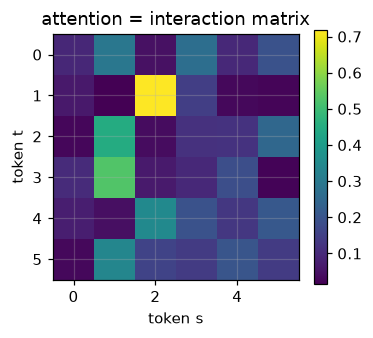

In [7]:
batch, tokens, d = 2, 6, 16
Q, K, V = torch.randn(batch, tokens, d), torch.randn(batch, tokens, d), torch.randn(batch, tokens, d)

scores = torch.einsum("btd,bsd->bts", Q, K) / math.sqrt(d)   # who interacts with whom
A = scores.softmax(dim=-1)
out = torch.einsum("bts,bsd->btd", A, V)
print("attention matrix:", tuple(A.shape), " output:", tuple(out.shape))

plt.figure(figsize=(3.6, 3)); plt.imshow(A[0].detach(), cmap="viridis"); plt.colorbar()
plt.title("attention = interaction matrix"); plt.xlabel("token s"); plt.ylabel("token t"); plt.show()

### Automatic differentiation: calculus done by the computer

Training uses **gradient descent**, $\theta \leftarrow \theta - \eta\nabla_\theta L$, and PyTorch computes every derivative with the chain rule (backpropagation). The same machinery can differentiate a network's output with respect to *time or space*, and that is what lets us put physics equations into the loss.

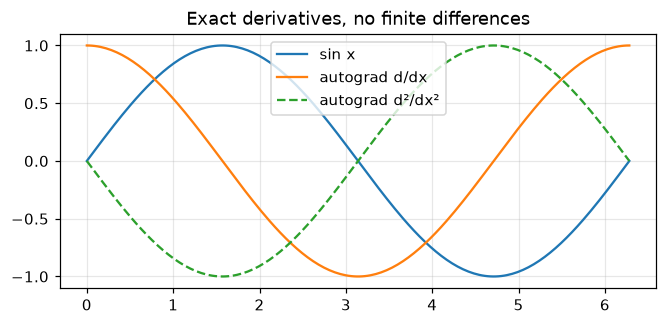

In [8]:
x = torch.linspace(0, 2 * math.pi, 200, requires_grad=True)
y = torch.sin(x)
dy = torch.autograd.grad(y.sum(), x, create_graph=True)[0]    # d/dx sin = cos
d2y = torch.autograd.grad(dy.sum(), x)[0]                       # d2/dx2 sin = -sin

xs = x.detach()
plt.figure(figsize=(7, 3))
plt.plot(xs, y.detach(), label="sin x")
plt.plot(xs, dy.detach(), label="autograd d/dx")
plt.plot(xs, d2y, "--", label="autograd d²/dx²")
plt.legend(); plt.title("Exact derivatives, no finite differences"); plt.show()

---
## Part 2: A physics-informed neural network (PINN)

### The physics: a damped harmonic oscillator

A mass on a spring with friction obeys Newton's second law:

$$m\frac{d^2x}{dt^2} + \mu\frac{dx}{dt} + kx = 0$$

We take $m=1$, $\mu = 2\delta = 4$, $k=\omega_0^2=400$, with $x(0)=1$ and $\dot x(0)=0$. This case (under-damped) has an exact solution we can use to check the network:

$$x(t) = e^{-\delta t}\,2A\cos(\phi + \omega t),\quad \omega=\sqrt{\omega_0^2-\delta^2}$$

**The challenge:** we only get **10 measurements**, all from the first third of the motion. Can the network predict the rest?

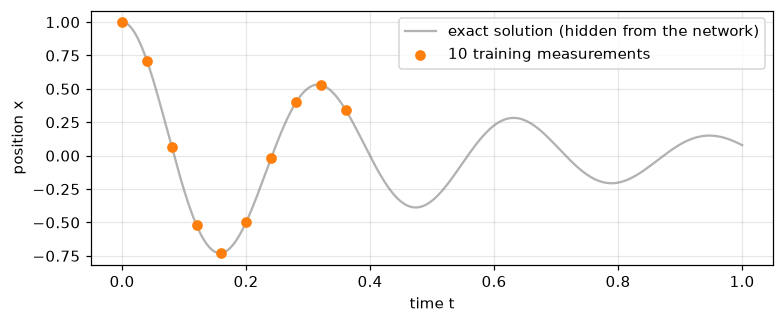

In [9]:
d, w0 = 2.0, 20.0
mu_true, k = 2 * d, w0 ** 2

def exact_solution(t):
    w = math.sqrt(w0 ** 2 - d ** 2)
    phi = math.atan(-d / w)
    A = 1 / (2 * math.cos(phi))
    return torch.exp(-d * t) * 2 * A * torch.cos(phi + w * t)

t_full = torch.linspace(0, 1, 500).view(-1, 1)
x_full = exact_solution(t_full)

t_data = t_full[0:200:20]            # 10 points, only for t <= 0.36
x_data = x_full[0:200:20]

plt.figure(figsize=(8, 3))
plt.plot(t_full, x_full, color="gray", alpha=0.6, label="exact solution (hidden from the network)")
plt.scatter(t_data, x_data, color="tab:orange", zorder=3, label="10 training measurements")
plt.xlabel("time t"); plt.ylabel("position x"); plt.legend(); plt.show()

In [10]:
class FCN(nn.Module):
    # A plain fully connected network: t -> x(t)
    def __init__(self, n_in=1, n_out=1, n_hidden=32, n_layers=3):
        super().__init__()
        layers = [nn.Linear(n_in, n_hidden), nn.Tanh()]
        for _ in range(n_layers - 1):
            layers += [nn.Linear(n_hidden, n_hidden), nn.Tanh()]
        layers += [nn.Linear(n_hidden, n_out)]
        self.net = nn.Sequential(*layers)

    def forward(self, t):
        return self.net(t)

def plot_fit(model, title, t_phys=None):
    with torch.no_grad():
        pred = model(t_full)
    plt.figure(figsize=(8, 3))
    plt.plot(t_full, x_full, color="gray", alpha=0.6, label="exact")
    plt.plot(t_full, pred, color="tab:blue", lw=2, label="neural network")
    plt.scatter(t_data, x_data, color="tab:orange", zorder=3, label="data")
    if t_phys is not None:
        plt.scatter(t_phys, torch.zeros_like(t_phys) - 1.1, s=12, color="tab:green", marker="^", label="physics points")
    plt.ylim(-1.3, 1.3); plt.title(title); plt.xlabel("t"); plt.legend(loc="upper right"); plt.show()

### Attempt 1: pure data fitting (ordinary machine learning)

Loss: $\;L = \frac{1}{N}\sum_i \big(\hat x(t_i) - x_i\big)^2$

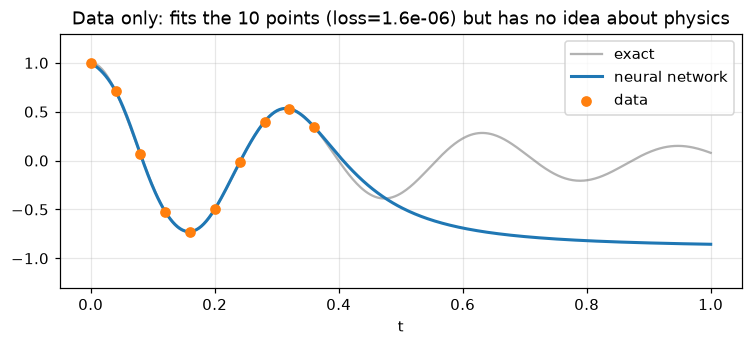

In [11]:
torch.manual_seed(123)
nn_model = FCN()
opt = torch.optim.Adam(nn_model.parameters(), lr=1e-3)
for step in range(3000):
    opt.zero_grad()
    loss = ((nn_model(t_data) - x_data) ** 2).mean()
    loss.backward(); opt.step()
plot_fit(nn_model, f"Data only: fits the 10 points (loss={loss.item():.1e}) but has no idea about physics")

### Attempt 2: a physics-informed network

We add a second term: the network's output must satisfy the differential equation at 30 "physics points" spread over the whole time interval. Autograd gives us $\hat x'$ and $\hat x''$ exactly.

$$L = \underbrace{\frac1N\sum_i\big(\hat x(t_i)-x_i\big)^2}_{\text{fit the data}} \;+\; \lambda\,\underbrace{\frac1M\sum_j\Big(\hat x''(t_j) + \mu\,\hat x'(t_j) + k\,\hat x(t_j)\Big)^2}_{\text{obey Newton's law}}$$

No extra measurements are needed for the physics points. They are just times at which we *check the equation*. Watch the prediction improve as training runs (about 20k steps, 30–60 s on a laptop).

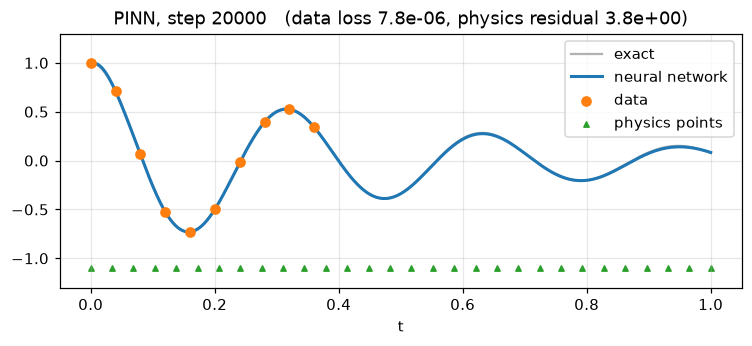

trained in 20.5 s


In [12]:
torch.manual_seed(123)
pinn = FCN()
opt = torch.optim.Adam(pinn.parameters(), lr=1e-4)
t_phys = torch.linspace(0, 1, 30).view(-1, 1).requires_grad_(True)
lam = 1e-4

history = []
t0 = time.time()
for step in range(20001):
    opt.zero_grad()
    # data loss
    loss_data = ((pinn(t_data) - x_data) ** 2).mean()
    # physics loss: residual of  x'' + mu x' + k x = 0
    x_hat = pinn(t_phys)
    dx = torch.autograd.grad(x_hat, t_phys, torch.ones_like(x_hat), create_graph=True)[0]
    d2x = torch.autograd.grad(dx, t_phys, torch.ones_like(dx), create_graph=True)[0]
    residual = d2x + mu_true * dx + k * x_hat
    loss_phys = (residual ** 2).mean()

    loss = loss_data + lam * loss_phys
    loss.backward(); opt.step()
    history.append((loss_data.item(), loss_phys.item()))

    if step % 2500 == 0:
        clear_output(wait=True)
        plot_fit(pinn, f"PINN, step {step}   (data loss {loss_data.item():.1e}, physics residual {loss_phys.item():.1e})", t_phys.detach())
print(f"trained in {time.time() - t0:.1f} s")

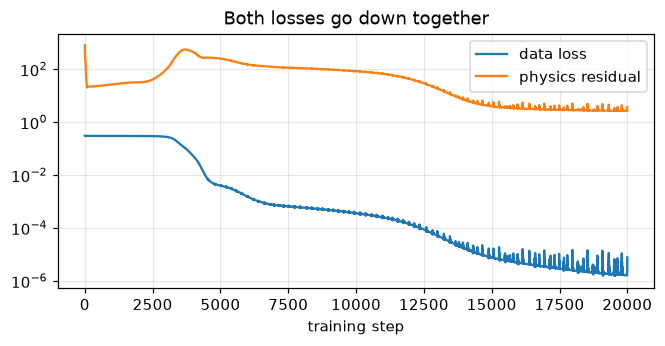

mean error over the whole interval   plain NN: 0.403    PINN: 0.004


In [13]:
h = np.array(history)
plt.figure(figsize=(7, 3))
plt.semilogy(h[:, 0], label="data loss"); plt.semilogy(h[:, 1], label="physics residual")
plt.xlabel("training step"); plt.legend(); plt.title("Both losses go down together"); plt.show()

with torch.no_grad():
    err_nn = (nn_model(t_full) - x_full).abs().mean().item()
    err_pinn = (pinn(t_full) - x_full).abs().mean().item()
print(f"mean error over the whole interval   plain NN: {err_nn:.3f}    PINN: {err_pinn:.3f}")

---
## Part 3: Scientific discovery, learning an unknown constant

Now flip the problem around. Suppose we **do not know the friction coefficient $\mu$**, but we have noisy measurements of the motion. We make $\mu$ a learnable parameter, just like the weights, and let gradient descent find it.

This is called an **inverse problem**. It is how PINNs are used to estimate material properties, viscosities, or reaction rates from experiments.

step      0   mu = -0.001


step   5000   mu = 4.259


step  10000   mu = 7.257


step  15000   mu = 5.592


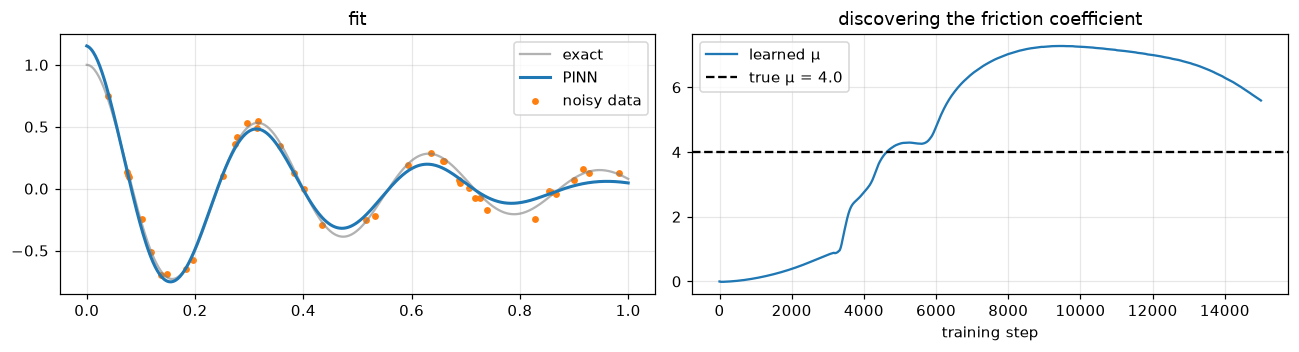

In [14]:
torch.manual_seed(123)
t_obs = torch.rand(40).view(-1, 1)
x_obs = exact_solution(t_obs) + 0.04 * torch.randn_like(t_obs)   # noisy sensor readings

pinn_inv = FCN()
mu = nn.Parameter(torch.zeros(1))                 # start with a wrong guess: no friction
opt = torch.optim.Adam(list(pinn_inv.parameters()) + [mu], lr=1e-3)
t_phys = torch.linspace(0, 1, 30).view(-1, 1).requires_grad_(True)
lam_data = 1e4

mus = []
for step in range(15001):
    opt.zero_grad()
    x_hat = pinn_inv(t_phys)
    dx = torch.autograd.grad(x_hat, t_phys, torch.ones_like(x_hat), create_graph=True)[0]
    d2x = torch.autograd.grad(dx, t_phys, torch.ones_like(dx), create_graph=True)[0]
    loss_phys = ((d2x + mu * dx + k * x_hat) ** 2).mean()
    loss_data = ((pinn_inv(t_obs) - x_obs) ** 2).mean()
    loss = loss_phys + lam_data * loss_data
    loss.backward(); opt.step()
    mus.append(mu.item())
    if step % 5000 == 0:
        print(f"step {step:6d}   mu = {mu.item():.3f}")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.3))
with torch.no_grad():
    ax[0].plot(t_full, x_full, color="gray", alpha=0.6, label="exact")
    ax[0].plot(t_full, pinn_inv(t_full), lw=2, label="PINN")
ax[0].scatter(t_obs, x_obs, s=12, color="tab:orange", label="noisy data"); ax[0].legend(); ax[0].set_title("fit")
ax[1].plot(mus, label="learned μ"); ax[1].axhline(mu_true, color="k", ls="--", label=f"true μ = {mu_true}")
ax[1].set_xlabel("training step"); ax[1].legend(); ax[1].set_title("discovering the friction coefficient")
plt.tight_layout(); plt.show()

### Takeaways

* A neural network is a stack of tensor operations, $\sigma(W\mathbf x+\mathbf b)$, trained with calculus (autograd plus gradient descent).
* On its own, a network fits data but knows nothing about the world outside that data.
* **Physics in the loss function** acts as a very strong prior: 10 data points plus Newton's law are enough to predict the whole motion.
* The same framework **discovers unknown physical parameters** from noisy data.

**Limitation:** a PINN is trained for *one* set of conditions. Change the initial condition and you must retrain. **Demo 2 (neural operators)** fixes this by learning the whole *solution operator*.